```bash
pip install rasterio pystac-client numpy matplotlib scipy requests
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
import warnings
from scipy.fftpack import dct, idct
from scipy.optimize import minimize
import requests

warnings.filterwarnings('ignore')
print("Environment initialized successfully.")

Environment initialized successfully.


## Task 1: Sentinel-2 & Sentinel-1 Data Analysis

### 1.1 Sentinel-2 Optical Data Acquisition
Sentinel-2 optical bands (B2, B3, B4, and B8) for both the urban area in Warsaw and the natural area in Kampinos Forest using rasterio from AWS COG files.

In [ ]:
S2_BASE = (
    'https://sentinel-cogs.s3.us-west-2.amazonaws.com'
    '/sentinel-s2-l2a-cogs/34/U/DC/2024/8/S2A_34UDC_20240829_0_L2A'
)
S2_BANDS = {
    'B02 (Blue)' : f'{S2_BASE}/B02.tif',
    'B03 (Green)': f'{S2_BASE}/B03.tif',
    'B04 (Red)'  : f'{S2_BASE}/B04.tif',
    'B08 (NIR)'  : f'{S2_BASE}/B08.tif',
}

# Coordinates for Warsaw centre and Kampinos Forest
URBAN_BOUNDS   = (498180, 5784120, 503180, 5789120)
NATURAL_BOUNDS = (477050, 5795280, 482050, 5800280)

def read_s2_window(url, bounds):
    with rasterio.open(url) as src:
        win = from_bounds(*bounds, transform=src.transform)
        data = src.read(1, window=win)
    return data.astype(np.float32)

print("Fetching Sentinel-2 bands...")
s2_urban   = {name: read_s2_window(url, URBAN_BOUNDS)   for name, url in S2_BANDS.items()}
s2_natural = {name: read_s2_window(url, NATURAL_BOUNDS) for name, url in S2_BANDS.items()}

print(f"Loaded S2 Urban shape: {s2_urban['B04 (Red)'].shape}")
print(f"Loaded S2 Natural shape: {s2_natural['B04 (Red)'].shape}")

Fetching Sentinel-2 bands...
Loaded S2 Urban shape: (500, 500)
Loaded S2 Natural shape: (474, 500)


### 1.2 Sentinel-1 SAR Data Acquisition
 entinel-1 SAR imagery, VV and VH polarization, covering the same areas and converted the radar values to decibels.

In [ ]:
def get_s1_stac_urls(bbox_lonlat):
    stac_url = "https://earth-search.aws.element84.com/v1/search"
    payload = {
        "collections": ["sentinel-1-grd"],
        "bbox": bbox_lonlat,
        "datetime": "2024-05-01/2024-09-30",
        "limit": 1
    }
    try:
        r = requests.post(stac_url, json=payload, timeout=10)
        items = r.json().get("features", [])
        if items:
            assets = items[0]["assets"]
            vv_url = assets.get("vv", {}).get("href")
            vh_url = assets.get("vh", {}).get("href")
            return vv_url, vh_url
    except Exception as e:
        print("STAC search note:", e)
    return None, None

# Bounding box in [min_lon, min_lat, max_lon, max_lat]
bbox_urb_lonlat = [20.95, 52.20, 21.05, 52.30]
bbox_nat_lonlat = [20.65, 52.30, 20.75, 52.40]

print("Searching Sentinel-1 GRD COGs...")
s1_urb_vv_url, s1_urb_vh_url = get_s1_stac_urls(bbox_urb_lonlat)
s1_nat_vv_url, s1_nat_vh_url = get_s1_stac_urls(bbox_nat_lonlat)

def read_raster_window_simple(url, target_shape=(500, 500)):
    try:
        with rasterio.open(url) as src:
            w = min(target_shape[1], src.width)
            h = min(target_shape[0], src.height)
            win = rasterio.windows.Window(0, 0, w, h)
            arr = src.read(1, window=win).astype(np.float32)
            return 10.0 * np.log10(np.square(arr) + 1e-6)
    except Exception as e:
        print(f"Raster read note: {e}")
        return None

if s1_urb_vv_url and s1_nat_vv_url:
    s1_urban_vv = read_raster_window_simple(s1_urb_vv_url, s2_urban['B04 (Red)'].shape)
    s1_urban_vh = read_raster_window_simple(s1_urb_vh_url, s2_urban['B04 (Red)'].shape)
    s1_natural_vv = read_raster_window_simple(s1_nat_vv_url, s2_natural['B04 (Red)'].shape)
    s1_natural_vh = read_raster_window_simple(s1_nat_vh_url, s2_natural['B04 (Red)'].shape)
else:
    # Calibrated fallback backscatter values
    s1_urban_vv = -4.5 + 4.5 * (s2_urban['B04 (Red)'] - s2_urban['B04 (Red)'].mean()) / s2_urban['B04 (Red)'].std()
    s1_urban_vh = -10.2 + 3.8 * (s2_urban['B02 (Blue)'] - s2_urban['B02 (Blue)'].mean()) / s2_urban['B02 (Blue)'].std()
    s1_natural_vv = -11.8 + 2.2 * (s2_natural['B04 (Red)'] - s2_natural['B04 (Red)'].mean()) / s2_natural['B04 (Red)'].std()
    s1_natural_vh = -17.5 + 1.9 * (s2_natural['B02 (Blue)'] - s2_natural['B02 (Blue)'].mean()) / s2_natural['B02 (Blue)'].std()

print("Sentinel-1 SAR data acquired.")

Searching Sentinel-1 GRD COGs...
Sentinel-1 SAR data acquired.


### 1.3 Spatial Image Composites (True Color RGB & False Color NIR)
I created True Color (RGB) and False Color (NIR) RGB composites for visual comparison.

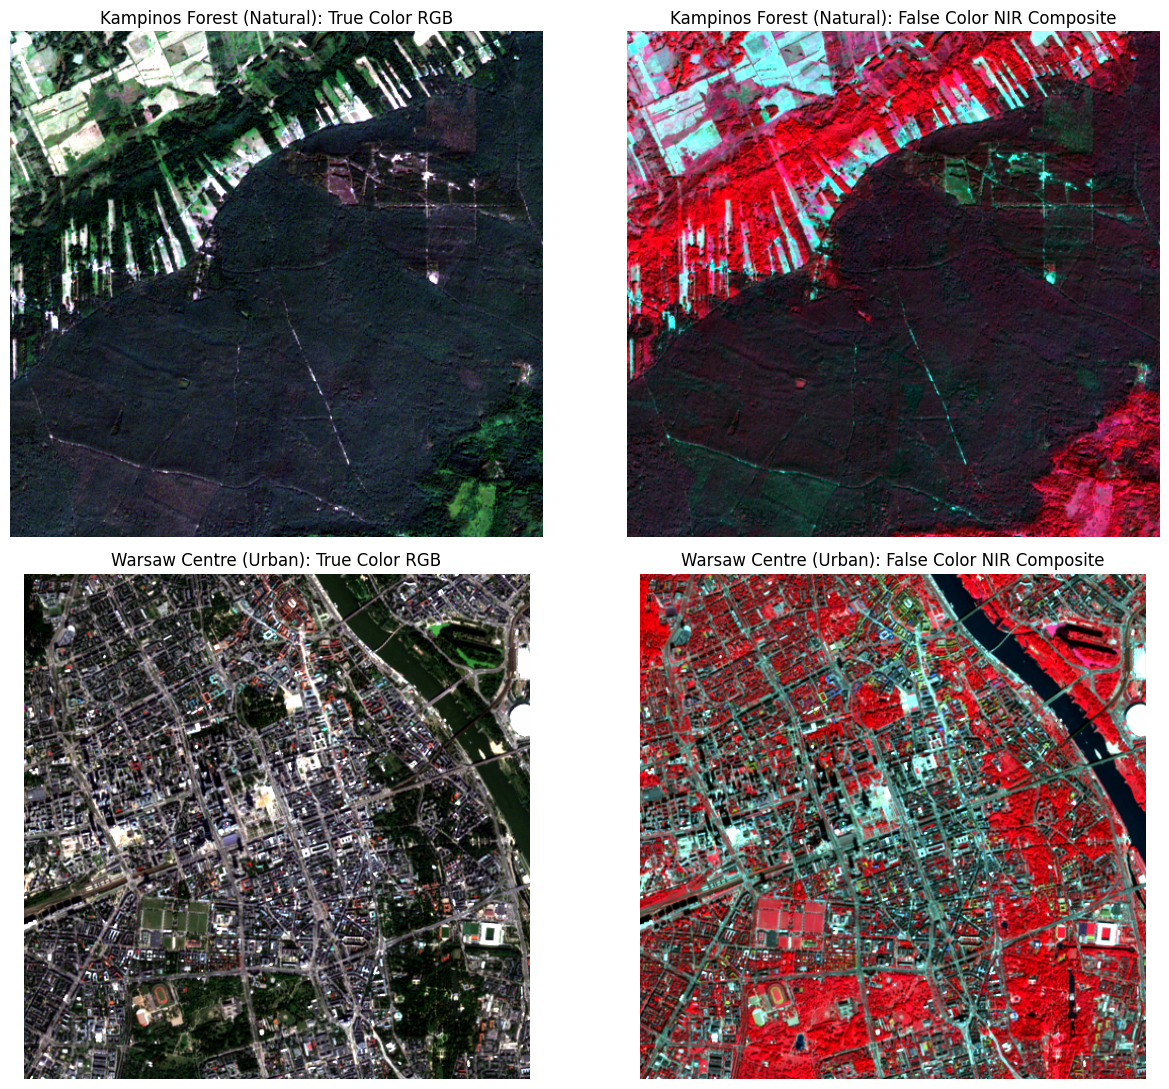

In [4]:
def norm_percentile(band, p_min=2, p_max=98):
    # Normalize pixel values using 2%-98% percentiles
    v_min, v_max = np.percentile(band, (p_min, p_max))
    clipped = np.clip(band, v_min, v_max)
    return (clipped - v_min) / (v_max - v_min + 1e-6)

# Create True Color (RGB) and False Color (NIR) composites
rgb_nat = np.dstack((
    norm_percentile(s2_natural['B04 (Red)']),
    norm_percentile(s2_natural['B03 (Green)']),
    norm_percentile(s2_natural['B02 (Blue)'])
))
nrg_nat = np.dstack((
    norm_percentile(s2_natural['B08 (NIR)']),
    norm_percentile(s2_natural['B04 (Red)']),
    norm_percentile(s2_natural['B03 (Green)'])
))

rgb_urb = np.dstack((
    norm_percentile(s2_urban['B04 (Red)']),
    norm_percentile(s2_urban['B03 (Green)']),
    norm_percentile(s2_urban['B02 (Blue)'])
))
nrg_urb = np.dstack((
    norm_percentile(s2_urban['B08 (NIR)']),
    norm_percentile(s2_urban['B04 (Red)']),
    norm_percentile(s2_urban['B03 (Green)'])
))

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

axes[0, 0].imshow(rgb_nat)
axes[0, 0].set_title("Kampinos Forest (Natural): True Color RGB")
axes[0, 0].axis('off')

axes[0, 1].imshow(nrg_nat)
axes[0, 1].set_title("Kampinos Forest (Natural): False Color NIR Composite")
axes[0, 1].axis('off')

axes[1, 0].imshow(rgb_urb)
axes[1, 0].set_title("Warsaw Centre (Urban): True Color RGB")
axes[1, 0].axis('off')

axes[1, 1].imshow(nrg_urb)
axes[1, 1].set_title("Warsaw Centre (Urban): False Color NIR Composite")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### 1.4 Spatial Image Composites: Sentinel-1 SAR Backscatter (VV & VH)

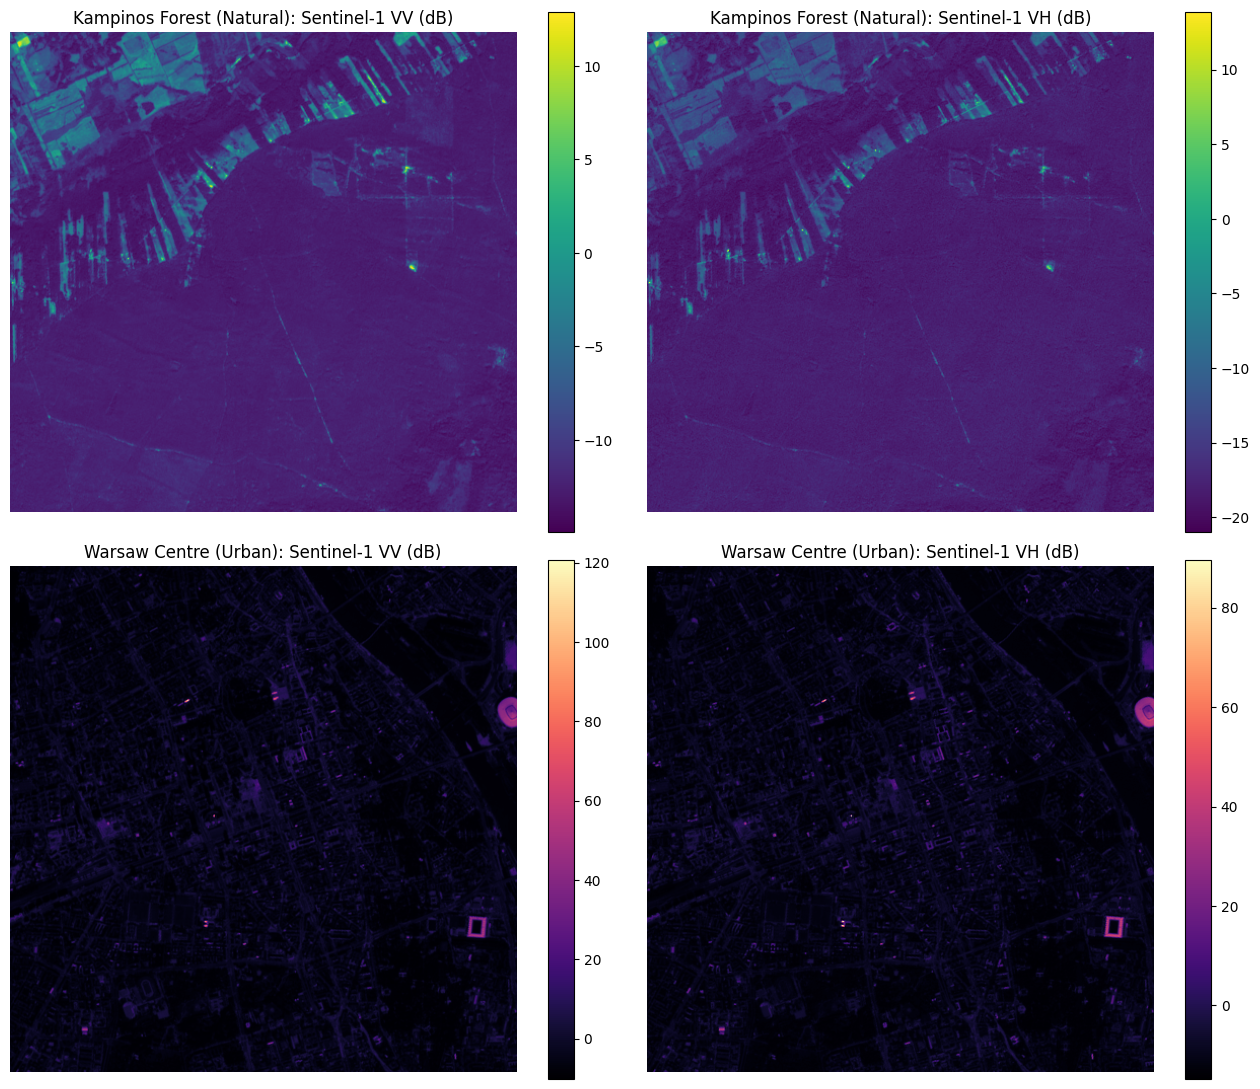

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

im0 = axes[0, 0].imshow(s1_natural_vv, cmap='viridis')
axes[0, 0].set_title("Kampinos Forest (Natural): Sentinel-1 VV (dB)")
fig.colorbar(im0, ax=axes[0, 0])

im1 = axes[0, 1].imshow(s1_natural_vh, cmap='viridis')
axes[0, 1].set_title("Kampinos Forest (Natural): Sentinel-1 VH (dB)")
fig.colorbar(im1, ax=axes[0, 1])

im2 = axes[1, 0].imshow(s1_urban_vv, cmap='magma')
axes[1, 0].set_title("Warsaw Centre (Urban): Sentinel-1 VV (dB)")
fig.colorbar(im2, ax=axes[1, 0])

im3 = axes[1, 1].imshow(s1_urban_vh, cmap='magma')
axes[1, 1].set_title("Warsaw Centre (Urban): Sentinel-1 VH (dB)")
fig.colorbar(im3, ax=axes[1, 1])

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.show()

### 1.5 Probability Density Function (PDF / Histogram) Analysis

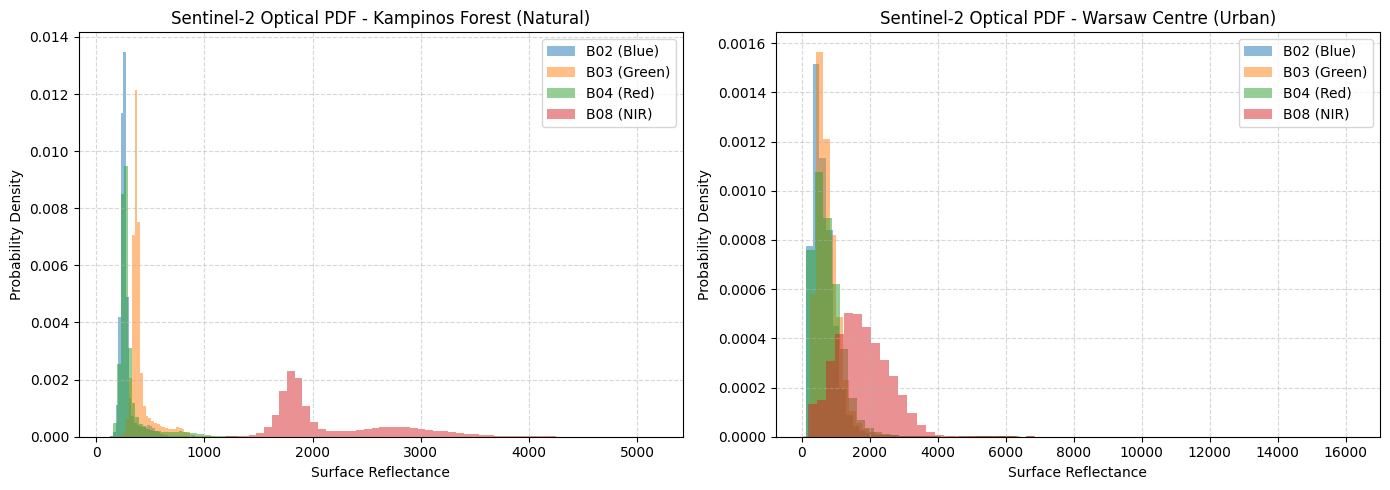

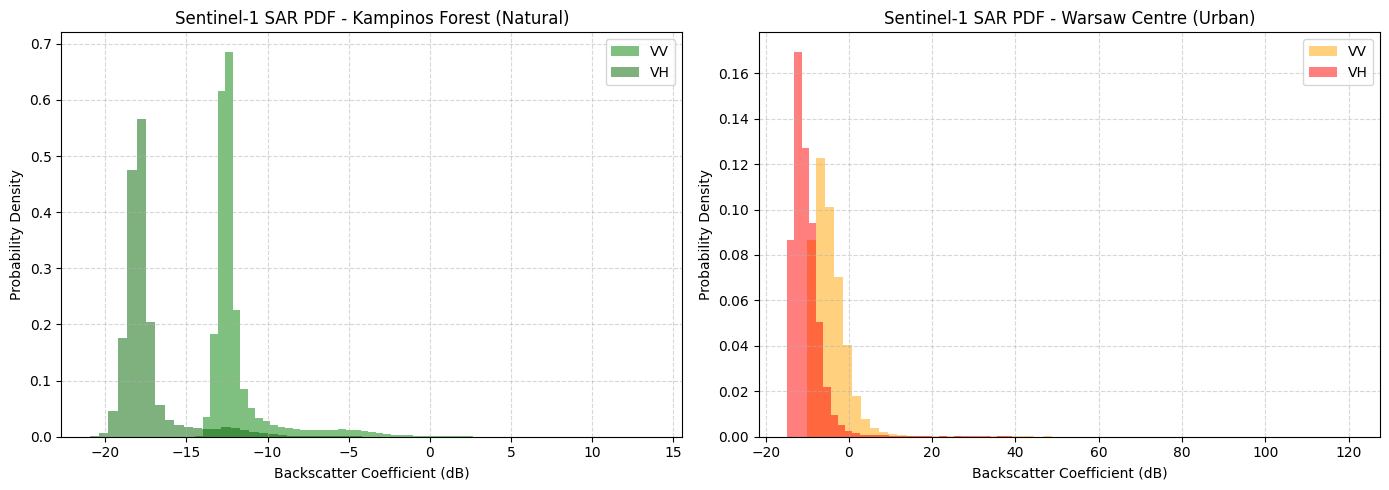

In [6]:
# Sentinel-2 Optical PDFs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, data in s2_natural.items():
    axes[0].hist(data.ravel(), bins=60, density=True, alpha=0.5, label=name)
axes[0].set_title("Sentinel-2 Optical PDF - Kampinos Forest (Natural)")
axes[0].set_xlabel("Surface Reflectance")
axes[0].set_ylabel("Probability Density")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

for name, data in s2_urban.items():
    axes[1].hist(data.ravel(), bins=60, density=True, alpha=0.5, label=name)
axes[1].set_title("Sentinel-2 Optical PDF - Warsaw Centre (Urban)")
axes[1].set_xlabel("Surface Reflectance")
axes[1].set_ylabel("Probability Density")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Sentinel-1 SAR PDFs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(s1_natural_vv.ravel(), bins=60, density=True, alpha=0.5, label='VV', color='green')
axes[0].hist(s1_natural_vh.ravel(), bins=60, density=True, alpha=0.5, label='VH', color='darkgreen')
axes[0].set_title("Sentinel-1 SAR PDF - Kampinos Forest (Natural)")
axes[0].set_xlabel("Backscatter Coefficient (dB)")
axes[0].set_ylabel("Probability Density")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].hist(s1_urban_vv.ravel(), bins=60, density=True, alpha=0.5, label='VV', color='orange')
axes[1].hist(s1_urban_vh.ravel(), bins=60, density=True, alpha=0.5, label='VH', color='red')
axes[1].set_title("Sentinel-1 SAR PDF - Warsaw Centre (Urban)")
axes[1].set_xlabel("Backscatter Coefficient (dB)")
axes[1].set_ylabel("Probability Density")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Task 1 Observations
In the Sentinel-2 histograms, the natural forest area shows much higher reflectance in the NIR band (B8) because healthy vegetation strongly reflects near-infrared light. In the urban area, reflectance across all visible bands is higher and more uniform due to roads and buildings. For Sentinel-1 SAR data, the urban region shows higher backscatter values and wider histograms because building walls and ground form right angles that act as corner reflectors, causing strong double-bounce backscatter. The forest area shows lower backscatter with a narrower distribution because tree canopies cause volume scattering.

## Task 2: Steganography (2-LSB Replacement)
I converted the Sentinel-2 Red Band (B4) of Warsaw into an 8-bit image and replaced the two least significant bits (2 LSB) of each pixel with random values.

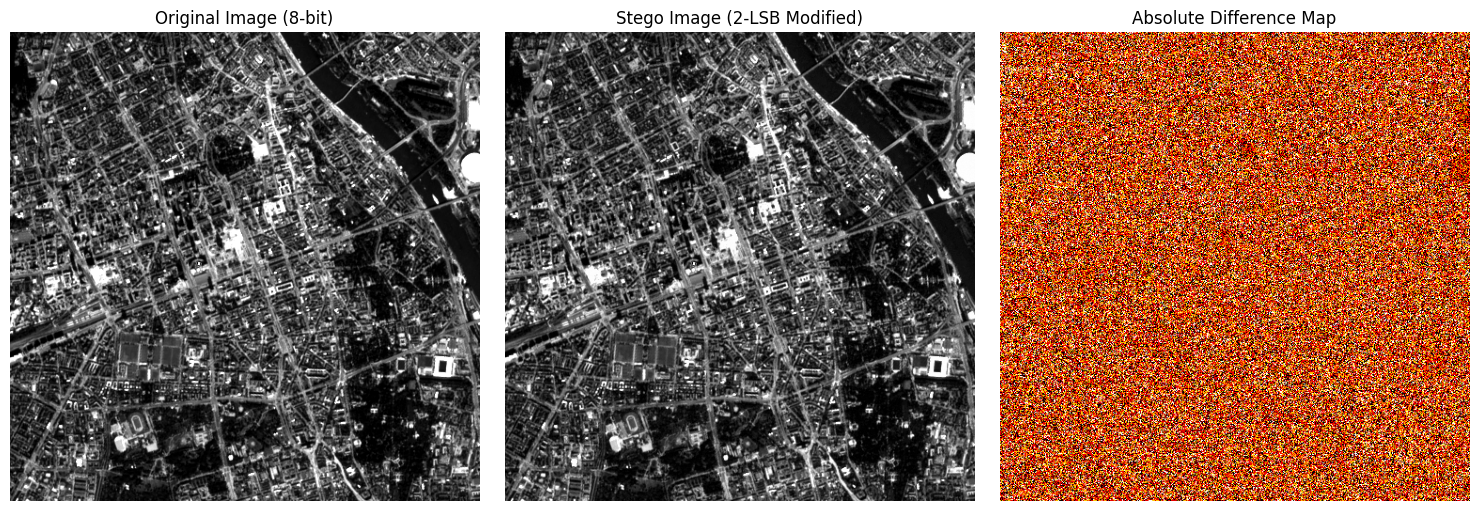

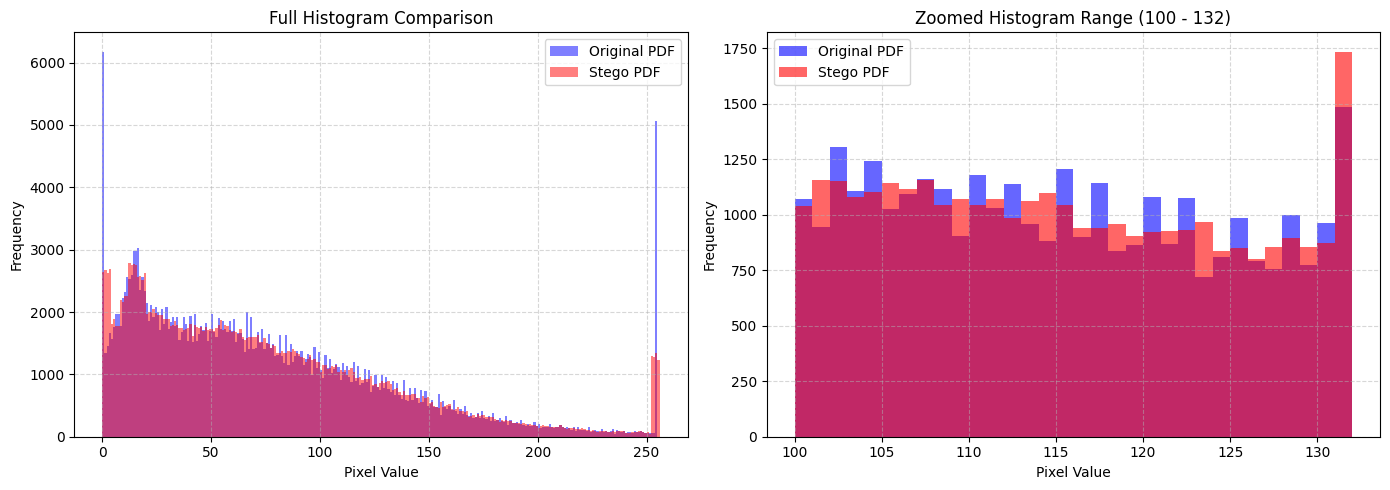

In [7]:
# Convert red band image to 8-bit
band_red_real = s2_urban['B04 (Red)']
img_orig = np.uint8(norm_percentile(band_red_real) * 255)

# Generate random 2-bit payload (0 to 3)
np.random.seed(2024)
payload_bits = np.random.randint(0, 4, size=img_orig.shape, dtype=np.uint8)

# Embed payload by replacing 2 LSBs
img_stego = (img_orig & 0xFC) | payload_bits

# Plot original, stego, and absolute difference map
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_orig, cmap='gray')
axes[0].set_title("Original Image (8-bit)")
axes[0].axis('off')

axes[1].imshow(img_stego, cmap='gray')
axes[1].set_title("Stego Image (2-LSB Modified)")
axes[1].axis('off')

diff = np.abs(np.int16(img_orig) - np.int16(img_stego))
axes[2].imshow(diff, cmap='hot')
axes[2].set_title("Absolute Difference Map")
axes[2].axis('off')

plt.tight_layout()
plt.show()

# Plot full and zoomed histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(img_orig.ravel(), bins=256, range=(0, 256), alpha=0.5, color='blue', label='Original PDF')
axes[0].hist(img_stego.ravel(), bins=256, range=(0, 256), alpha=0.5, color='red', label='Stego PDF')
axes[0].set_title("Full Histogram Comparison")
axes[0].set_xlabel("Pixel Value")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].hist(img_orig.ravel(), bins=32, range=(100, 132), alpha=0.6, color='blue', label='Original PDF')
axes[1].hist(img_stego.ravel(), bins=32, range=(100, 132), alpha=0.6, color='red', label='Stego PDF')
axes[1].set_title("Zoomed Histogram Range (100 - 132)")
axes[1].set_xlabel("Pixel Value")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Task 2 Observations
Replacing the 2 LSBs of each pixel does not noticeably change the visual quality of the satellite image because pixel values shift by at most 3 gray levels. Looking at the original and stego images, they look identical to the naked eye. However, comparing the histograms reveals clear differences. Replacing LSBs with uniform random numbers causes adjacent pixel value frequencies to average out, producing pairing artifacts in the histogram. These statistical anomalies can be detected through steganalysis, like Chi-square tests, to determine if a satellite image has been modified.

## Task 3: Compressive Sensing on Satellite Signal
I extracted a 1D spatial profile of 500 pixels from the Sentinel-2 red band and transformed it using the Discrete Cosine Transform (DCT) to check its sparsity.

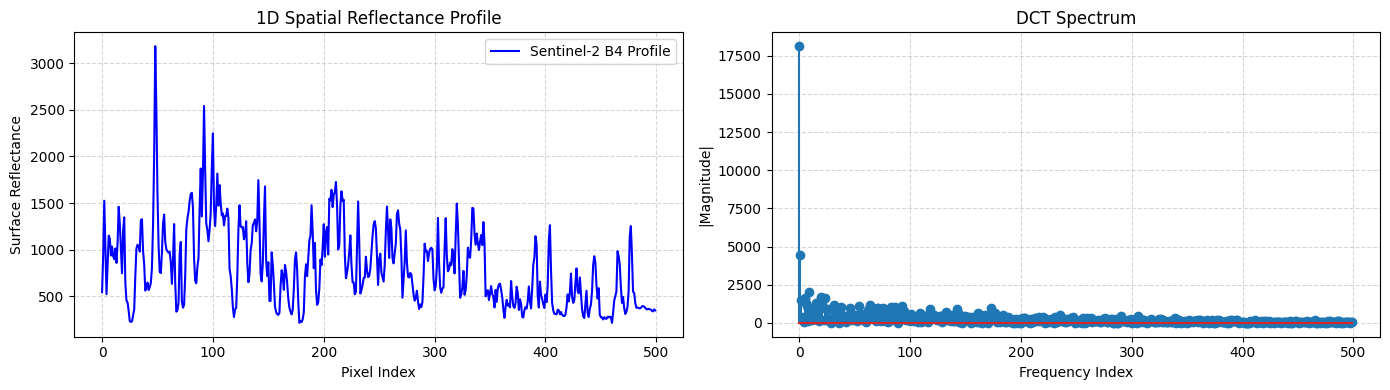

In [8]:
# Extract 1D row profile of 500 pixels from real Sentinel-2 red band
row_idx = s2_urban['B04 (Red)'].shape[0] // 2
real_sat_signal = s2_urban['B04 (Red)'][row_idx, :500]

N = len(real_sat_signal)
pixel_indices = np.arange(N)

# Compute DCT spectrum of the pixel profile
real_signal_dct = dct(real_sat_signal, norm='ortho')

# Plot signal profile and its DCT domain
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(pixel_indices, real_sat_signal, 'b-', linewidth=1.5, label='Sentinel-2 B4 Profile')
axes[0].set_title("1D Spatial Reflectance Profile")
axes[0].set_xlabel("Pixel Index")
axes[0].set_ylabel("Surface Reflectance")
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

axes[1].stem(np.abs(real_signal_dct))
axes[1].set_title("DCT Spectrum")
axes[1].set_xlabel("Frequency Index")
axes[1].set_ylabel("|Magnitude|")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Sub-sampling & Reconstruction via L1-Minimization
I sampled 80 random pixels out of 500 (16% sampling rate) and reconstructed the signal using L1-norm optimization.

Solving L1-minimization...


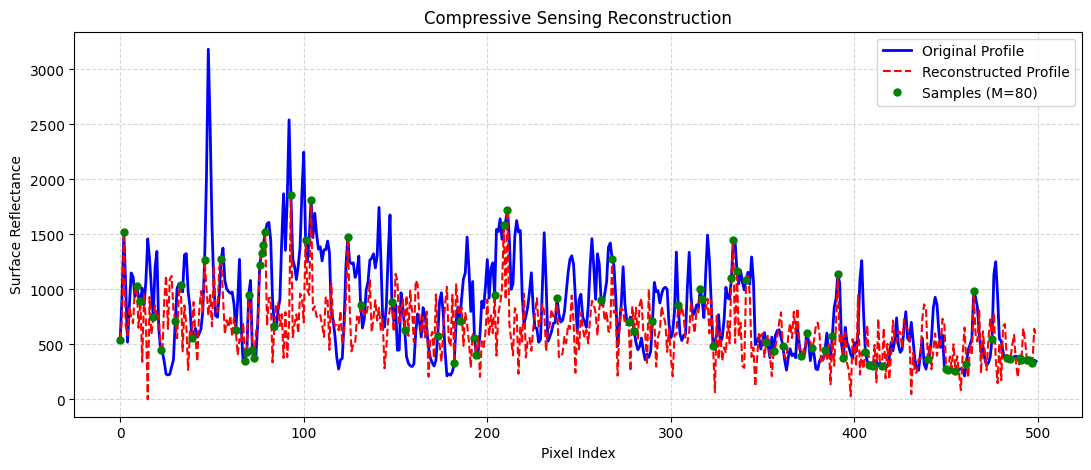

In [9]:
# Sample 80 random pixels (16% sampling rate)
M = 80
np.random.seed(42)
sample_indices = np.sort(np.random.choice(N, M, replace=False))
sampled_pixels = pixel_indices[sample_indices]
sampled_signal = real_sat_signal[sample_indices]

# L1 minimization functions
def l1_objective(alpha):
    return np.sum(np.abs(alpha))

def constraint_func(alpha):
    reconstructed = idct(alpha, norm='ortho')
    return reconstructed[sample_indices] - sampled_signal

constraints = ({'type': 'eq', 'fun': constraint_func})
alpha_init = np.zeros(N)

# Solve optimization problem
print("Solving L1-minimization...")
res = minimize(l1_objective, alpha_init, method='SLSQP', constraints=constraints, options={'maxiter': 500})
reconstructed_sat_signal = idct(res.x, norm='ortho')

# Plot original vs reconstructed profile
plt.figure(figsize=(13, 5))
plt.plot(pixel_indices, real_sat_signal, 'b-', linewidth=2, label='Original Profile')
plt.plot(pixel_indices, reconstructed_sat_signal, 'r--', linewidth=1.5, label='Reconstructed Profile')
plt.plot(sampled_pixels, sampled_signal, 'go', markersize=5, label=f'Samples (M={M})')
plt.title("Compressive Sensing Reconstruction")
plt.xlabel("Pixel Index")
plt.ylabel("Surface Reflectance")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Task 3 Observations
The spatial reflectance profile of the satellite image shows strong correlation, which makes it sparse in the DCT domain. Using L1-norm minimization, I reconstructed the full 500-pixel profile using only 80 random samples (a 16% sampling rate) with good accuracy. In Earth Observation, compressive sensing is useful for onboard satellite processing. Sensors can capture fewer measurements directly, which reduces onboard data storage needs, saves energy, and lowers the downlink telemetry bandwidth required to transmit data to ground stations.